In [ ]:
import pickle
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from matplotlib.patches import Patch
from nibabel.freesurfer import read_annot
from nilearn import plotting
from scipy.stats import wilcoxon

ROOT = Path.cwd()
if ROOT.name == 'figure_code':
    ROOT = ROOT.parent

DATA_DIR = ROOT / 'data'

BASE_DIR = DATA_DIR
ATLAS_TXT = BASE_DIR / 'maps' / 'Schaefer2018_300Parcels_17Networks_order.txt'
MAP_DIR = BASE_DIR / 'maps/fsaverage5'

LH_MESH = MAP_DIR / 'surf/lh.inflated'
RH_MESH = MAP_DIR / 'surf/rh.inflated'
LH_ANNOT = MAP_DIR / 'roi/lh.Schaefer2018_300Parcels_17Networks_order.annot'
RH_ANNOT = MAP_DIR / 'roi/rh.Schaefer2018_300Parcels_17Networks_order.annot'

FEATURE_ORDER = ['lv', 'mv', 'hv', 'sm']
FEATURE_LABELS = {'lv': 'Low visual', 'mv': 'Mid visual', 'hv': 'High visual', 'sm': 'Semantic'}

results = pd.read_csv(BASE_DIR / 'subs_group.csv')


In [2]:
def load_schaefer_labels(path):
    rows = []

    with open(path) as f:
        for line in f:
            parts = line.split()

            roi, label = int(parts[0]), parts[1]
            hemisphere = 'LH' if '_LH_' in label else ('RH' if '_RH_' in label else 'NA')
            match = re.search(r'_(?:LH|RH)_([^_]+)', label)
            network = match.group(1) if match else 'NA'

            rows.append({'roi': roi, 'label': label, 'hemisphere': hemisphere, 'network': network})

    return pd.DataFrame(rows)


labels = load_schaefer_labels(ATLAS_TXT)

In [3]:
def annot_to_vertex_values(annot_file, roi_values):
    labels_vertex, _, names = read_annot(str(annot_file))
    roi_values = np.asarray(roi_values, dtype=float)

    parcel_ids = np.arange(1, len(names))
    vertex_data = np.full(labels_vertex.shape, np.nan, dtype=float)

    for parcel_id, value in zip(parcel_ids, roi_values):
        vertex_data[labels_vertex == parcel_id] = value

    return vertex_data, labels_vertex


def plot_schaefer_surface(vec, cmap, vmin, vmax, title='', add_cbar=True, cbar_label=None, figsize=(10, 8)):
    vec = np.asarray(vec, dtype=float)
    lh_data, lh_labels = annot_to_vertex_values(LH_ANNOT, vec[:150])
    rh_data, rh_labels = annot_to_vertex_values(RH_ANNOT, vec[150:])

    fig, axes = plt.subplots(2, 2, figsize=figsize, subplot_kw={'projection': '3d'})

    views = [
        ('left', 'lateral', LH_MESH, lh_data, lh_labels, axes[0, 0]),
        ('right', 'lateral', RH_MESH, rh_data, rh_labels, axes[0, 1]),
        ('left', 'medial', LH_MESH, lh_data, lh_labels, axes[1, 0]),
        ('right', 'medial', RH_MESH, rh_data, rh_labels, axes[1, 1]),
    ]

    for hemi, view, mesh, data, parcel_labels, ax in views:
        plotting.plot_surf_stat_map(surf_mesh=str(mesh), stat_map=data, hemi=hemi, view=view, bg_map=np.ones(len(data)) * 0.5,
                                    darkness=None, cmap=cmap, colorbar=False, threshold=None, vmin=vmin, vmax=vmax, axes=ax)

        levels = sorted(np.unique(parcel_labels[parcel_labels > 0]))
        plotting.plot_surf_contours(surf_mesh=str(mesh), roi_map=parcel_labels, hemi=hemi, view=view, levels=levels,
                                    colors=['#545252'] * len(levels), legend=False, axes=ax)

    fig.suptitle(title, y=0.98)

    if add_cbar is True:
        sm = cm.ScalarMappable(norm=colors.Normalize(vmin=vmin, vmax=vmax), cmap=cmap)
        sm.set_array([])
        cax = fig.add_axes([0.35, 0.46, 0.30, 0.03])
        cbar = fig.colorbar(sm, cax=cax, orientation='horizontal')
        cbar.set_label(cbar_label)

    plt.tight_layout()
    return fig, axes

In [4]:
def feature_to_vec(df, q_thresh=0.05):
    q = df['q'].astype(float).to_numpy()
    keep = np.isfinite(q) & (q < q_thresh)

    vec = np.full(300, np.nan)
    roi = df.loc[keep, 'roi'].astype(int).to_numpy() - 1
    vec[roi] = df.loc[keep, 'accuracy'].to_numpy()

    return vec

/tmp/ipykernel_1380860/2641425252.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_1380860/2641425252.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_1380860/2641425252.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_1380860/2641425252.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


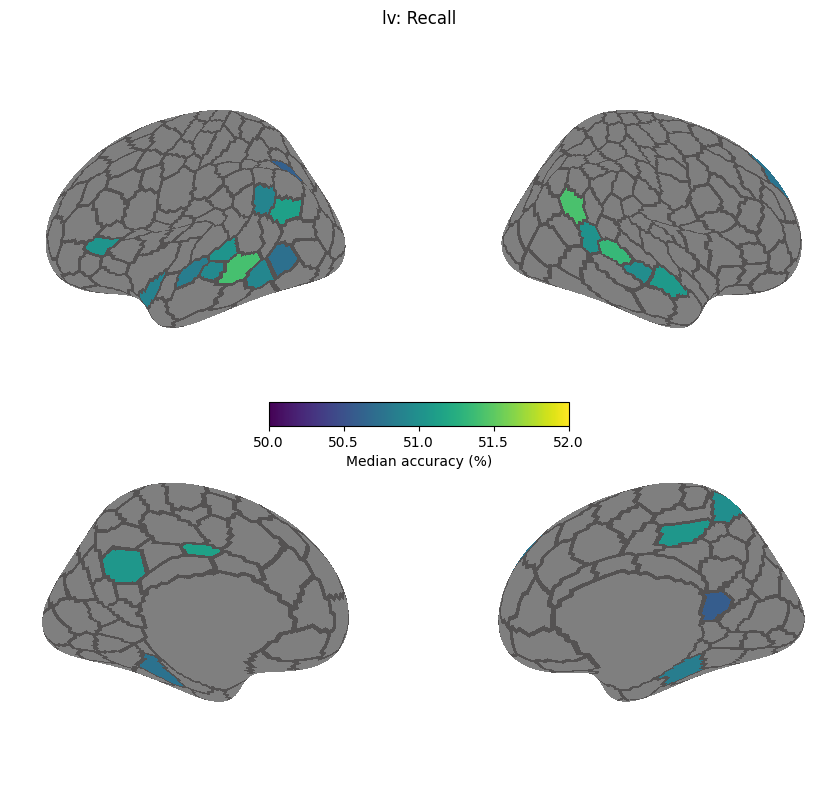

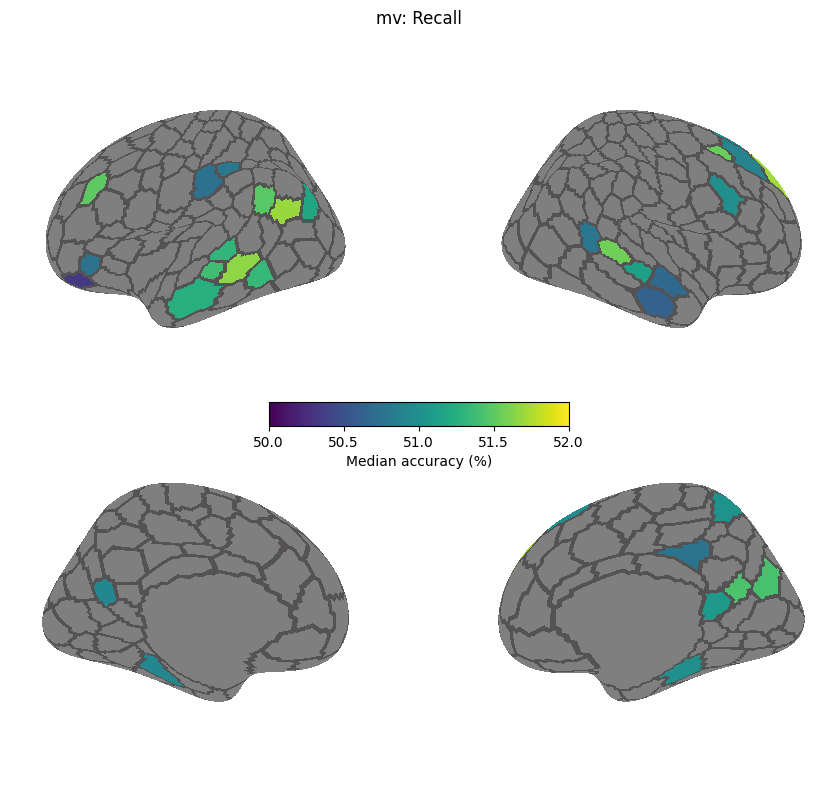

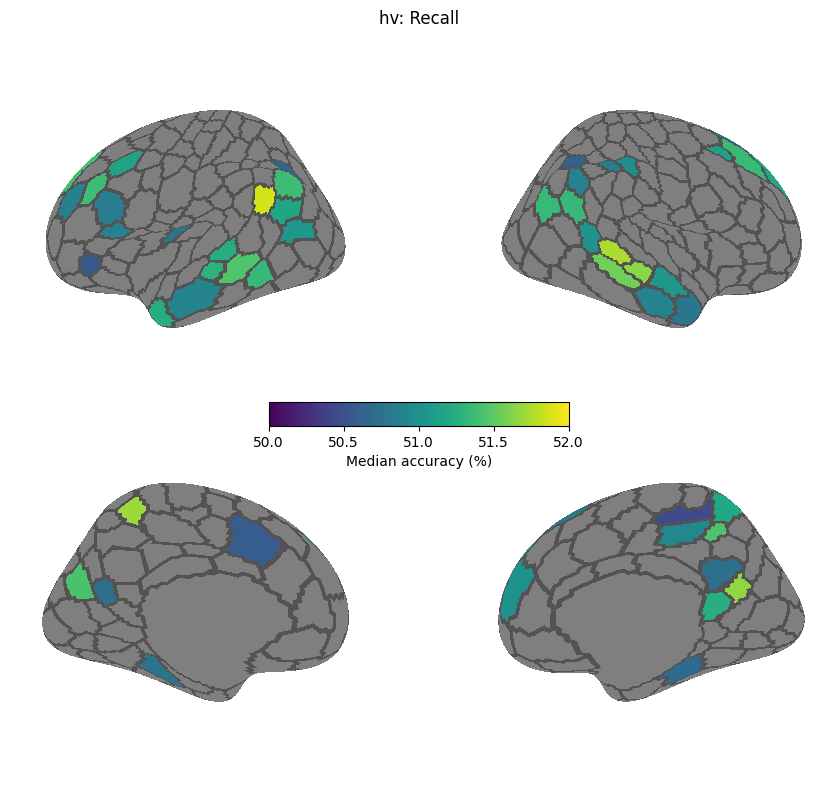

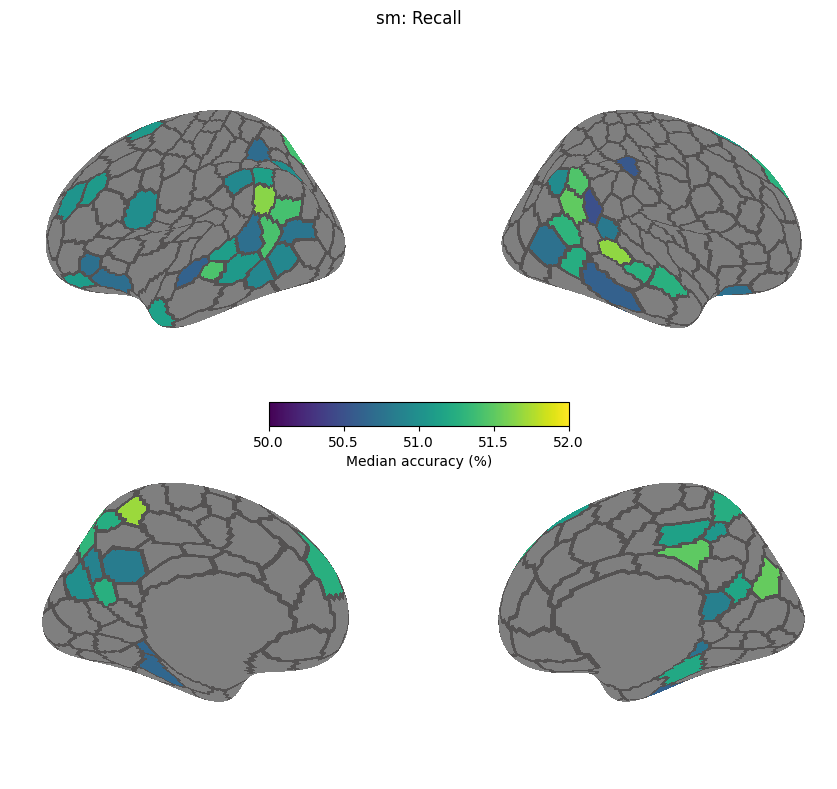

In [5]:
for feature in FEATURE_ORDER:
    plot_df = results.loc[results['feature'].eq(feature)].copy()
    plot_df['accuracy'] = plot_df['median_obs_rank_acc']*100 #use obs for display purpose
    vec = feature_to_vec(plot_df)

    plot_schaefer_surface(vec, cmap='viridis', vmin=50, vmax=52,
                          title=f'{feature}: Recall', cbar_label='Median accuracy (%)')

In [6]:
NETWORK_17_TO_8 = {
    'VisCent': 'Vis', 'VisPeri': 'Vis',
    'SomMotA': 'SomMot', 'SomMotB': 'SomMot',
    'DorsAttnA': 'DorsAttn', 'DorsAttnB': 'DorsAttn',
    'SalVentAttnA': 'SalVentAttn', 'SalVentAttnB': 'SalVentAttn',
    'LimbicA': 'Limbic', 'LimbicB': 'Limbic',
    'ContA': 'Cont', 'ContB': 'Cont', 'ContC': 'Cont',
    'TempPar': 'TempPar',
    'DefaultA': 'Default', 'DefaultB': 'Default', 'DefaultC': 'Default',
}

SYSTEM_ORDER = ['Vis', 'SomMot', 'DorsAttn', 'SalVentAttn', 'Limbic', 'Cont', 'TempPar', 'Default']

NETWORK_COLORS = {
    'Vis': '#C45161',
    'SomMot': '#E094A0',
    'DorsAttn': '#F2B6C0',
    'SalVentAttn': '#F2DDE1',
    'Limbic': '#CBC7D8',
    'Cont': '#8DB7D2',
    'TempPar': '#434279',
    'Default': '#7378DA',
}

labels_8 = labels.copy()
labels_8['system'] = labels_8['network'].map(NETWORK_17_TO_8)

if labels_8['system'].isna().any():
    missing = labels_8.loc[labels_8['system'].isna(), 'network'].unique().tolist()
    raise ValueError(f'Unmapped networks: {missing}')

In [7]:
def make_network_counts(results, labels):
    sig = results.loc[results['q'] < 0.05, ['roi', 'median_value']].copy()
    sig['abs_effect'] = sig['median_value'].abs()
    sig = sig.sort_values('abs_effect', ascending=False).drop_duplicates('roi')
    sig['positive'] = sig['median_value'] >= 0
    sig = sig.merge(labels[['roi', 'network']], on='roi', how='left')

    n_sig = sig.loc[sig['positive']].groupby('network').size().rename('n_sig')
    total = labels.groupby('network').size().rename('total_parcels')

    counts = pd.concat([n_sig, total], axis=1).fillna(0).astype(int)
    counts['prop'] = counts['n_sig'] / counts['total_parcels']

    return counts

def plot_network_counts(counts):
    piv = counts.sort_values(['n_sig', 'total_parcels'], ascending=False)
    x = np.arange(len(piv))
    lim = int(piv['total_parcels'].max())

    fig, ax = plt.subplots(figsize=(0.55 * len(piv) + 2, 5))

    ax.bar(x, piv['total_parcels'], color='#E8E8E8', edgecolor='#CCC', lw=0.5, zorder=1)
    ax.bar(x, piv['n_sig'], color='#C44E52', edgecolor='white', lw=0.7, zorder=3)

    for i, (_, row) in enumerate(piv.iterrows()):
        ax.text(i, row['total_parcels'] + 0.7, f'{row["n_sig"]:0.0f}/{row["total_parcels"]:0.0f}', ha='center', fontsize=8, color='#777')

    ax.set_xticks(x)
    ax.set_xticklabels(piv.index, rotation=45, ha='right', fontsize=9.5)
    ax.set_ylim(0, lim + 10)
    ax.set_ylabel('# positive ROIs surviving FDR (q < .05)', fontsize=8.5)
    ax.spines[['top', 'right']].set_visible(False)

    fig.tight_layout()

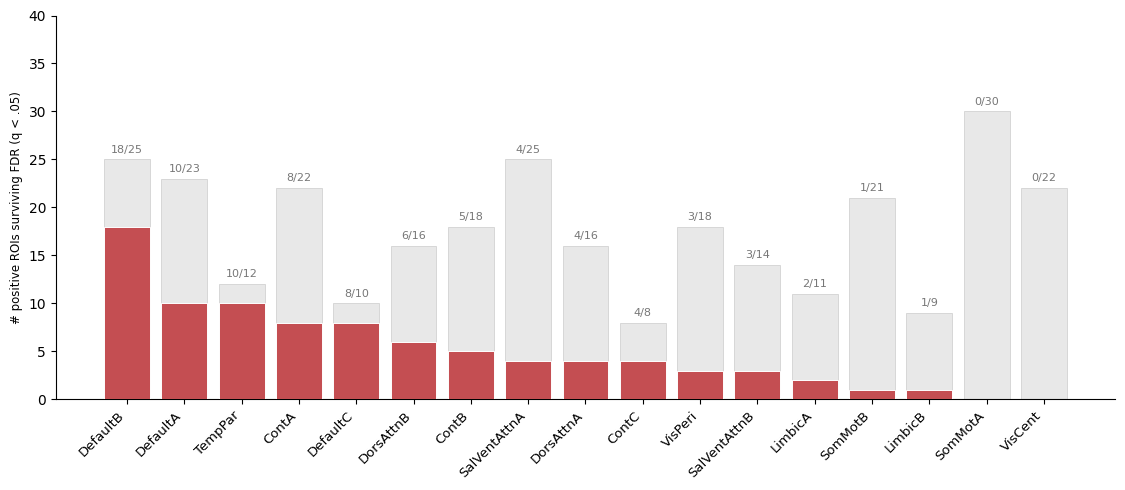

In [8]:
network_counts = make_network_counts(results, labels)
plot_network_counts(network_counts)

In [9]:
heat = results.merge(labels_8[['roi', 'system']], on='roi', how='left').copy()
heat['accuracy'] = heat['median_obs_rank_acc'] * 100 
heat['sig'] = heat['q'] < 0.05

heat_value = heat.groupby(['feature', 'system'])['accuracy'].median().unstack().reindex(index=FEATURE_ORDER, columns=SYSTEM_ORDER)
heat_nsig = heat.groupby(['feature', 'system'])['sig'].sum().unstack().reindex(index=FEATURE_ORDER, columns=SYSTEM_ORDER).fillna(0)
system_sizes = labels_8.groupby('system')['roi'].nunique().reindex(SYSTEM_ORDER)

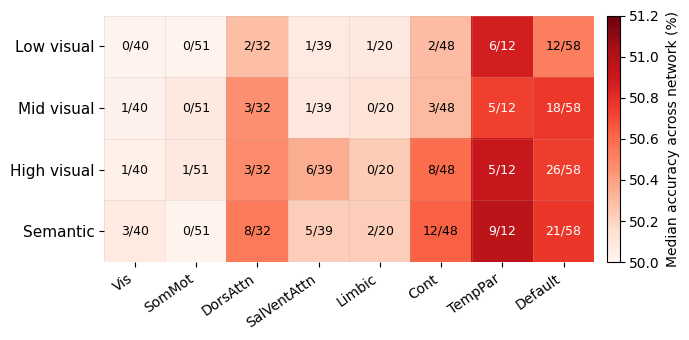

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))

vmin, vmax = 50, 51.2
cmap = plt.cm.Reds
im = ax.imshow(heat_value.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto')

ax.set_xticks(np.arange(len(SYSTEM_ORDER)))
ax.set_xticklabels(SYSTEM_ORDER, rotation=35, ha='right', fontsize=10)
ax.set_yticks(np.arange(len(FEATURE_ORDER)))
ax.set_yticklabels([FEATURE_LABELS[f] for f in FEATURE_ORDER], fontsize=11)

for i, feature in enumerate(FEATURE_ORDER):
    for j, system in enumerate(SYSTEM_ORDER):
        val = heat_value.loc[feature, system]
        nsig = int(heat_nsig.loc[feature, system])
        ntot = int(system_sizes.loc[system])

        rgba = im.cmap(im.norm(val))
        luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
        text_color = 'white' if luminance < 0.5 else 'black'

        ax.text(j, i, f'{nsig}/{ntot}', ha='center', va='center', fontsize=9, color=text_color)

cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.025)
cbar.set_label('Median accuracy across network (%)', fontsize=10)

ax.set_xticks(np.arange(-0.5, len(SYSTEM_ORDER), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(FEATURE_ORDER), 1), minor=True)
ax.grid(which='minor', linewidth=0.6, alpha=0.25)
ax.tick_params(which='minor', bottom=False, left=False)
ax.spines[['top', 'right', 'bottom', 'left']].set_visible(False)

plt.tight_layout()

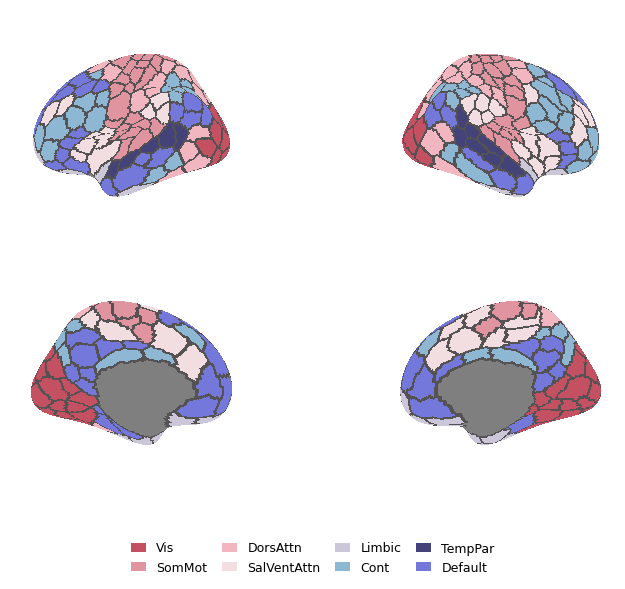

In [11]:
system_to_code = {system: i + 1 for i, system in enumerate(SYSTEM_ORDER)}

network_profile = labels_8.set_index('roi')['system'].map(system_to_code).reindex(np.arange(1, 301)).to_numpy(dtype=float)

if np.isnan(network_profile).any():
    missing = (np.where(np.isnan(network_profile))[0] + 1).tolist()
    raise ValueError(f'Missing system assignment for ROI(s): {missing}')

network_cmap = colors.ListedColormap([NETWORK_COLORS[s] for s in SYSTEM_ORDER])

fig, axes = plot_schaefer_surface(network_profile, cmap=network_cmap, vmin=0.5, vmax=8.5,
                                  title='', add_cbar=False, figsize=(8.4, 6))

handles = [Patch(facecolor=NETWORK_COLORS[s], edgecolor='none', label=s) for s in SYSTEM_ORDER]
fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, -0.01), ncol=4,
           frameon=False, fontsize=9, columnspacing=1.2, handlelength=1.2)

fig.subplots_adjust(bottom=0.14)

In [ ]:
TRANSMODAL = {'DefaultA', 'DefaultB', 'DefaultC', 'TempPar', 'ContA', 'ContB', 'ContC'}
SENSORY = {'VisCent', 'VisPeri', 'SomMotA', 'SomMotB'}
ZONES = ['sensory', 'intermediate', 'transmodal']
ZONE_COLORS = {'sensory': '#4C72B0', 'intermediate': '#9A9A9A', 'transmodal': '#C44E52'}

VALUE_COL = 'obs_rank_acc'
CHANCE = 0.5

In [17]:
PM_CSV = BASE_DIR / 'subs_subject.csv'


def load_zone_data():
    pm = pd.read_csv(PM_CSV)
    pm = pm.loc[pm['method'].eq('OT')].copy()

    zone_labels = labels[['roi', 'network']].copy()
    zone_labels['zone'] = np.select(
        [zone_labels['network'].isin(TRANSMODAL), zone_labels['network'].isin(SENSORY)],
        ['transmodal', 'sensory'],
        default='intermediate',
    )

    d = pm.merge(zone_labels, on='roi', how='left')
    d = d.groupby(['subject', 'roi', 'network', 'zone'], as_index=False)[VALUE_COL].mean()

    subject_zone = d.groupby(['subject', 'zone'])[VALUE_COL].median().unstack()
    diffs = (subject_zone['transmodal'] - subject_zone['sensory']).dropna()
    stat, p = wilcoxon(diffs, alternative='greater')

    return d, diffs, stat, p


d, diffs, stat, p = load_zone_data()

print(f'n = {len(diffs)}; median difference = {np.median(diffs):.4f}; '
      f'{(diffs > 0).sum()}/{len(diffs)} subjects > 0; W = {stat:.0f}; p = {p:.4g}')

n = 16; median difference = 0.0060; 13/16 subjects > 0; W = 129; p = 0.0002899


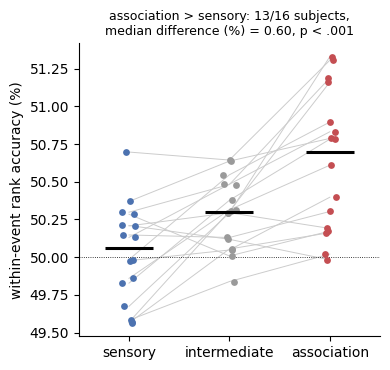

In [18]:
def plot_zone_panel(d, diffs, p, seed=0):
    rng = np.random.default_rng(seed)
    zsub = (d.groupby(['subject', 'zone'])[VALUE_COL].median().unstack().reindex(columns=ZONES)) * 100

    fig, ax = plt.subplots(figsize=(4, 3.8))
    x = np.arange(len(ZONES))

    for _, row in zsub.iterrows():
        ax.plot(x, row.values, color='0.8', lw=0.7, zorder=1)

    for i, zone in enumerate(ZONES):
        values = zsub[zone].to_numpy()
        ax.scatter(i + rng.uniform(-0.07, 0.07, len(values)), values, s=24, color=ZONE_COLORS[zone], linewidth=0, zorder=3)
        ax.hlines(np.median(values), i - 0.24, i + 0.24, color='k', lw=2.2, zorder=4)

    diff_pct = np.median(diffs) * 100
    p_text = 'p < .001' if p < 0.001 else f'p = {p:.3f}'

    ax.axhline(CHANCE * 100, color='k', lw=0.6, ls=':')
    ax.set_xticks(x)
    ax.set_xticklabels(['sensory', 'intermediate', 'association'], fontsize=10)
    ax.set_xlim(-0.5, 2.5)
    ax.set_ylabel('within-event rank accuracy (%)')
    ax.set_title(f'association > sensory: {(diffs > 0).sum()}/{len(diffs)} subjects,\n'
                 f'median difference (%) = {diff_pct:.2f}, {p_text}', fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)

    fig.tight_layout()



plot_zone_panel(d, diffs, p)